# ConjunctivaGuard PoC, Part 4: damaging photos on purpose (module M9)

**Goal:** make bad-phone-photo versions of good D01 eyelid photos (glare, blur, dark) at 3 strengths, keeping the clean original next to each one.

No GPU needed. Run the cells top to bottom with ▶. About 5 minutes.

**Words from the lesson:** *synthetic damage* (added on purpose), *severity* (mild / moderate / severe), *clean reference* (the undamaged original), *reproducible* (same seed, same result).

### Cell 1: setup
Connects Drive, gets D01 again (Colab forgets between sessions) and reads the **split file from Part 2**, so every photo keeps its train / val / test place.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os, glob, zipfile, gdown
import pandas as pd

D01_LINK_ID = 'YOUR_D01_FILE_ID'
OUT = '/content/drive/MyDrive/ConjunctivaGuard/poc_outputs'
if not os.path.exists('/content/D01.zip'):
    gdown.download(id=D01_LINK_ID, output='/content/D01.zip', quiet=True)
if not os.path.exists('/content/work/D01'):
    with zipfile.ZipFile('/content/D01.zip') as zf:
        zf.extractall('/content/work/D01')
D01_DIR = glob.glob('/content/work/D01/*/')[0]

splits = pd.read_csv(os.path.join(OUT, 'D01_splits.csv'))
use = splits[splits.split.isin(['val', 'test']) & splits.eval_image].reset_index(drop=True)
print('Photos we will damage (one per eyelid): val', int((use.split == 'val').sum()),
      '| test', int((use.split == 'test').sum()))

Mounted at /content/drive
Photos we will damage (one per eyelid): val 60 | test 75


### Cell 2: the damage tools (just run it)
| Damage | How it is made | mild / moderate / severe |
|---|---|---|
| **glare** | a bright white patch placed on the eyelid (never on the empty background) | covers 5% / 15% / 30% of the eyelid |
| **blur** | the eyelid colours are smeared (Gaussian blur) | blur width 1 / 2 / 4 pixels |
| **dark** | brightness lowered, plus a little grain like a real dark photo | 75% / 50% / 30% of the brightness kept |

`seed_for` makes a fixed number from the file name, so the same photo always gets the same damage (**reproducible**).

`measure` gives 3 simple numbers about the eyelid: **brightness**, **sharpness** (how crisp the details are) and **glare share** (part of the eyelid that is almost white). This is a first taste of the quality profile (M3) in Part 5.

In [ ]:
import zlib
import numpy as np
import cv2
from PIL import Image

LEVELS = ['mild', 'moderate', 'severe']
DAMAGES = ['glare', 'blur', 'dark']
# how strong each level is (the "knobs")
GLARE_COVER = {'mild': 0.05, 'moderate': 0.15, 'severe': 0.30}   # share of the eyelid covered
BLUR_SIGMA  = {'mild': 1.0,  'moderate': 2.0,  'severe': 4.0}    # blur width in pixels
DARK_FACTOR = {'mild': 0.75, 'moderate': 0.50, 'severe': 0.30}   # brightness kept

def load_strip(path):
    # photo as numbers: rgb (0-255) and the eyelid area (where the PNG is not see-through)
    im = np.asarray(Image.open(path).convert('RGBA')).astype(np.float32)
    return im[..., :3], im[..., 3] > 0

def seed_for(file, damage, level):
    # a fixed number from the file name: same photo + same damage = same result every run
    return zlib.crc32(f'{file}|{damage}|{level}'.encode())

def add_glare(rgb, tissue, level, rng):
    ys, xs = np.nonzero(tissue)
    k = rng.integers(len(ys))
    cy, cx = ys[k], xs[k]                                  # glare centre: a random eyelid pixel
    d = np.sqrt((np.arange(rgb.shape[0])[:, None] - cy) ** 2 + (np.arange(rgb.shape[1])[None, :] - cx) ** 2)
    target = max(1, int(GLARE_COVER[level] * tissue.sum()))
    radius = np.sort(d[tissue])[target - 1]                # grow until the wanted share is covered
    feather = 2.0
    w = np.clip((radius - d) / feather + 0.5, 0, 1) * tissue
    white = np.array([255.0, 252.0, 248.0])
    out = rgb * (1 - w[..., None]) + white * w[..., None]
    return out, w > 0.5

def add_blur(rgb, tissue, level, rng=None):
    a = tissue.astype(np.float32)
    s = BLUR_SIGMA[level]
    num = cv2.GaussianBlur(rgb * a[..., None], (0, 0), s)  # blur only the eyelid colours,
    den = cv2.GaussianBlur(a, (0, 0), s)[..., None]        # not the empty background
    out = np.where(den > 1e-3, num / np.maximum(den, 1e-3), rgb)
    return out, None

def add_dark(rgb, tissue, level, rng):
    out = rgb * DARK_FACTOR[level]
    out = out + rng.normal(0, 2.0 + 6.0 * (1 - DARK_FACTOR[level]), rgb.shape)   # dark photos are grainy
    return out, None

FUNCS = {'glare': add_glare, 'blur': add_blur, 'dark': add_dark}

def damage(rgb, tissue, file, kind, level):
    rng = np.random.default_rng(seed_for(file, kind, level))
    out, glare_mask = FUNCS[kind](rgb, tissue, level, rng)
    out = np.clip(out, 0, 255)
    out[~tissue] = 0
    return out.astype(np.uint8), glare_mask

def to_png(rgb, tissue, path):
    rgba = np.dstack([rgb.astype(np.uint8), (tissue * 255).astype(np.uint8)])
    Image.fromarray(rgba, 'RGBA').save(path)

def measure(rgb, tissue):
    # three simple numbers about the eyelid (a preview of the quality profile M3)
    t = tissue
    rgb = rgb.astype(np.float32)
    bright = rgb[t].mean()
    gray = cv2.cvtColor(rgb.astype(np.uint8), cv2.COLOR_RGB2GRAY).astype(np.float32)
    lap = cv2.Laplacian(gray, cv2.CV_32F)
    inner = cv2.erode(t.astype(np.uint8), np.ones((5, 5), np.uint8)) > 0   # ignore the cut edge
    sharp = float(lap[inner].var()) if inner.sum() > 20 else float('nan')
    glare = float(((rgb.min(axis=2) > 235) & t).sum() / t.sum())
    return {'brightness': float(bright), 'sharpness': sharp, 'glare_share': glare}


### Cell 3: see the damage on one eyelid
Rows: glare, blur, dark. Columns: clean, mild, moderate, severe.

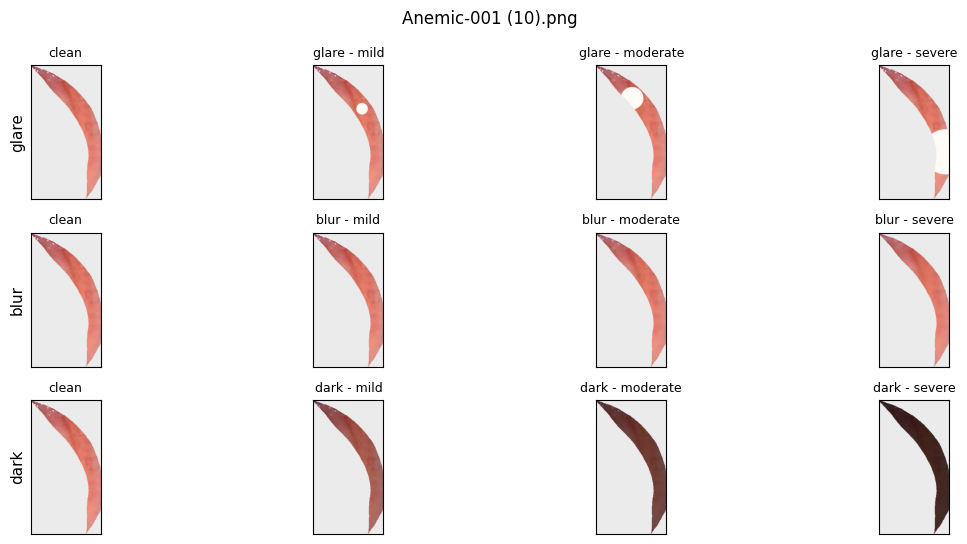

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def show(rgb, tissue):
    out = np.full(rgb.shape, 235, np.uint8)          # light grey background
    out[tissue] = rgb[tissue]
    return out

example = use[use.split == 'test'].iloc[0].file
rgb, tissue = load_strip(os.path.join(D01_DIR, example))
fig, axes = plt.subplots(3, 4, figsize=(13, 5.5))
for r, kind in enumerate(DAMAGES):
    axes[r, 0].imshow(show(rgb.astype(np.uint8), tissue)); axes[r, 0].set_title('clean', fontsize=9)
    axes[r, 0].set_ylabel(kind, fontsize=11)
    for c, level in enumerate(LEVELS, start=1):
        out, _ = damage(rgb, tissue, example, kind, level)
        axes[r, c].imshow(show(out, tissue)); axes[r, c].set_title(f'{kind} - {level}', fontsize=9)
for ax in axes.ravel():
    ax.set_xticks([]); ax.set_yticks([])
plt.suptitle(example); plt.tight_layout(); plt.show()

### Cell 4: the numbers for that eyelid
How brightness, sharpness and glare share change as the damage gets stronger.

In [ ]:
rows = [{'damage': 'none', 'level': 'clean', **measure(rgb, tissue)}]
for kind in DAMAGES:
    for level in LEVELS:
        out, _ = damage(rgb, tissue, example, kind, level)
        rows.append({'damage': kind, 'level': level, **measure(out, tissue)})
display(pd.DataFrame(rows).round(2))

,damage,level,brightness,sharpness,glare_share
0,none,clean,148.02,43.15,0.00
1,glare,mild,153.38,71.00,0.05
2,glare,moderate,164.94,79.38,0.14
3,glare,severe,175.78,52.71,0.30
4,blur,mild,147.52,6.81,0.00
5,blur,moderate,147.53,2.48,0.00
6,blur,severe,147.54,1.84,0.00
7,dark,mild,110.51,136.05,0.00
8,dark,moderate,73.53,236.21,0.00
9,dark,severe,43.89,352.89,0.00


### Cell 5: build the small damaged set (D04-PoC)
For every **val** and **test** eyelid: the clean photo plus 9 damaged versions (3 damages × 3 levels), saved as PNG files in your Drive (`poc_outputs/D04_poc/…`), with a table (`D04_poc_manifest.csv`) listing each file, its split, label, damage, level and the 3 numbers.

Training photos are **not** damaged here: in the PoC the model learns only from clean photos, and damage is used to test it. About 3–5 minutes.

In [ ]:
from tqdm.auto import tqdm

BASE = os.path.join(OUT, 'D04_poc')
records = []
for _, r in tqdm(use.iterrows(), total=len(use)):
    rgb, tissue = load_strip(os.path.join(D01_DIR, r.file))
    versions = [('none', 'clean', rgb.astype(np.uint8))]
    for kind in DAMAGES:
        for level in LEVELS:
            versions.append((kind, level, damage(rgb, tissue, r.file, kind, level)[0]))
    for kind, level, img in versions:
        folder = os.path.join(BASE, f'{kind}_{level}')
        os.makedirs(folder, exist_ok=True)
        path = os.path.join(folder, r.file)
        if not os.path.exists(path):
            to_png(img, tissue, path)
        records.append({'file': r.file, 'group': r.group, 'label': r.label, 'split': r.split,
                        'damage': kind, 'level': level, 'path': path,
                        'seed': seed_for(r.file, kind, level) if kind != 'none' else None,
                        **measure(img, tissue)})
man = pd.DataFrame(records)
man.to_csv(os.path.join(OUT, 'D04_poc_manifest.csv'), index=False)
print('Images saved:', len(man), '| damage versions:', man.groupby(['damage', 'level']).ngroups)

  0%|          | 0/135 [00:00<?, ?it/s]

/tmp/ipykernel_983/358157496.py:59: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  Image.fromarray(rgba, 'RGBA').save(path)


Images saved: 1350 | damage versions: 10


### Cell 6: three safety checks
1. **Reproducible:** make 5 damaged images again and compare with the saved files pixel by pixel. Must be identical.
2. **No leakage:** every damaged copy has the **same split** as its original photo.
3. **Glare is the planned size:** about 5% / 15% / 30% of the eyelid.

In [ ]:
check = man[man.damage != 'none'].sample(5, random_state=0)
same = []
for _, r in check.iterrows():
    rgb, tissue = load_strip(os.path.join(D01_DIR, r.file))
    again = damage(rgb, tissue, r.file, r.damage, r.level)[0]
    saved = np.asarray(Image.open(r.path).convert('RGBA'))[..., :3]
    same.append(np.array_equal(again[tissue], saved[tissue]))
print('1. Same seed, same damage:', 'yes ✅' if all(same) else 'NO ❌')

orig = dict(zip(splits.file, splits.split))
ok = (man.split == man.file.map(orig)).all()
print('2. Damaged copies kept their split:', 'yes ✅' if ok else 'NO ❌')

g = man[man.damage == 'glare'].groupby('level').glare_share.mean().reindex(LEVELS)
print('3. Glare share (target 0.05 / 0.15 / 0.30):', ' / '.join(f'{v:.2f}' for v in g))

1. Same seed, same damage: yes ✅
2. Damaged copies kept their split: yes ✅
3. Glare share (target 0.05 / 0.15 / 0.30): 0.04 / 0.14 / 0.29


### Cell 7: what the damage does on average (test photos)
Each number is compared with the **same eyelid's clean photo** (clean = 100%). This shows that each damage type hurts a different quality, and that stronger levels hurt more.

In [ ]:
t = man[man.split == 'test'].copy()
clean = t[t.damage == 'none'].set_index('file')
for m in ('brightness', 'sharpness'):
    t[m + '_%'] = 100 * t[m] / t.file.map(clean[m])
summary = (t[t.damage != 'none']
           .groupby(['damage', 'level'])[['brightness_%', 'sharpness_%', 'glare_share']]
           .mean().reindex(pd.MultiIndex.from_product([DAMAGES, LEVELS])).round(2))
display(summary)

brightness_%  sharpness_%  glare_share
glare mild            104.45       615.78         0.04
      moderate        113.87       730.84         0.14
      severe          127.20       654.66         0.29
blur  mild             99.64        32.65         0.00
      moderate         99.63        25.31         0.00
      severe           99.61        22.59         0.00
dark  mild             74.62      1362.94         0.00
      moderate         49.63      2662.19         0.00
      severe           29.63      4061.70         0.00

### Part 4 done ✅
**Outputs to check:** the text output of **Cells 1, 6 and 7**, and screenshots of **Cell 3** and **Cell 4**.

**What you learned**
- We damage good photos **on purpose** so we always know the **clean reference**.
- Each damage hurts a different thing: glare adds white, blur removes sharpness, dark removes brightness.
- **Same seed, same damage** makes the experiment repeatable.
- Damaged copies stay in their original split, so there is still **no leakage**.

**Next (Part 5):** the anemia model learns from clean training photos, then we test it on these damaged photos: *how much worse does it get as damage grows?*